# Image Annotation Types in Python

| # | Annotation type | What it stores | Typical use |
|---|---|---|---|
| 1 | Image label (classification) | one tag per image | "Is this leaf healthy or diseased?" |
| 2 | Bounding box | rectangle `(x, y, w, h)` | object detection |
| 3 | Polygon | list of `(x, y)` corner points | precise outlines |
| 4 | Semantic mask | one class id per pixel | measuring areas |
| 5 | Instance masks | one mask per object | counting and separating objects |
| 6 | Keypoints | labelled points | landmarks (leaf tip, base) |

Then we **export** to the two most common formats: **COCO JSON** and **YOLO text files**.

**Libraries:** `numpy`, `opencv-python`, `matplotlib` (install with `pip install numpy opencv-python matplotlib`).

**Coordinate rule to remember:** the origin `(0, 0)` is the **top-left** corner. `x` goes right, `y` goes **down**.

In [5]:
!pip install numpy pandas matplotlib seaborn scikit-learn opencv-python tensorflow keras

  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached markdown_it_py-4.2.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   -------- ------------------------------- 8.9/44.0 MB 44.6 MB/s eta 0:00:01
   --------------- ------------------------ 17.0/44.0 MB 42.4 MB/s eta 0:00:01
   ----------------------- ---------------- 25.7/44.0 MB 41.8 MB/s eta 0:00:01
   ------------------------------- -------- 34.3/44.0 MB 41.7 MB/s eta 0:00:01
   ---------------------------------------  43.0/44.0 MB 41.6 MB/s eta 0:00:01
   ---------------------------------------- 44.0/44.0 MB 39.6 MB/s  0:00:01
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
    --------------------------------------- 9.2/384.1 MB 42.8 MB/s eta 0:00:09
   - -------------------------------------- 17.6/384.1 MB 40.6 MB/s eta 0:00:10
   -- ------------------------------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Annotating Two Tomato Leaves with Python

**Images:** `images/tomato_septoria_leaf_spot.jpg` (Septoria leaf spot) and `images/tomato_healthy.jpg` (healthy).

**What we will do**
1. Look at the images and decide what to label.
2. **Pre-label automatically:** leaf outline from colour, lesions from brown pixels.
3. Turn masks into **polygons** (the real annotation).
4. Compute **severity %** = lesion pixels / leaf pixels × 100.
5. **Export** COCO JSON, YOLO-seg text files and mask PNGs.

## 1. Setup and look at the images

tomato_healthy shape (height, width, channels): (256, 256, 3)
tomato_septoria_leaf_spot shape (height, width, channels): (256, 256, 3)


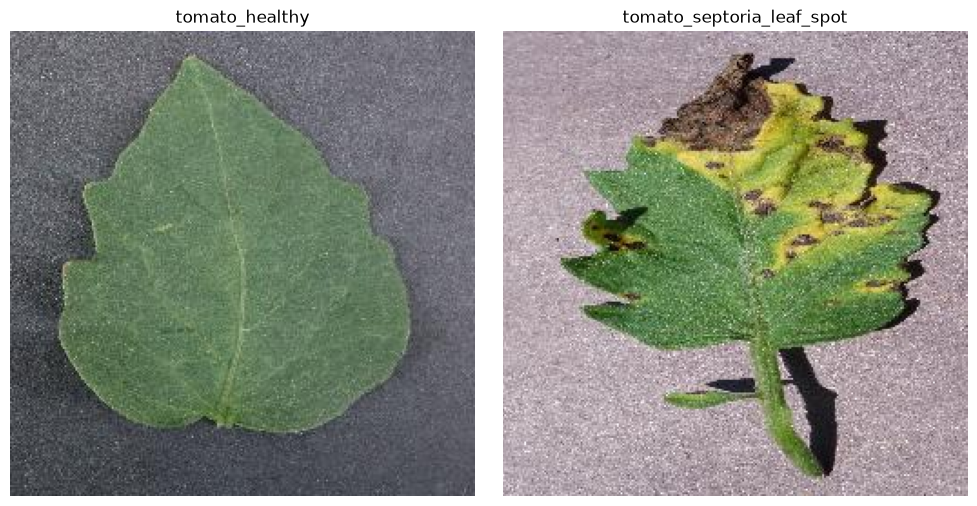

In [15]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

IMG_DIR = Path("images")
OUT = Path("annotation_output")
OUT.mkdir(exist_ok=True)
CLASSES = {"leaf": 1, "lesion": 2}          # mask values; 0 = background

def show(images, titles=None, figsize=(10, 5)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    axes = np.atleast_1d(axes)
    for i, (ax, im) in enumerate(zip(axes, images)):
        ax.imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB), cmap="gray" if im.ndim == 2 else None)
        ax.set_title(titles[i] if titles else ""); ax.axis("off")
    plt.tight_layout(); plt.show()

paths = sorted(IMG_DIR.glob("*.jpg"))
imgs = {p.stem: cv2.imread(str(p)) for p in paths}      # OpenCV loads as BGR
for name, im in imgs.items():
    print(name, "shape (height, width, channels):", im.shape)
show(list(imgs.values()), list(imgs.keys()))

**What to label** (from our guidelines):
- `leaf`: the whole blade, **without the stem (petiole)** and without shadow.
- `lesion`: brown or dead tissue, each separate spot as its own polygon. For Septoria we **do not** include the yellow halo.
- A healthy leaf gets a leaf polygon only.

## 2. Automatic leaf outline

The ground (pavement, dark cloth) is nearly **grey**, while the leaf has colour, even where it is brown. We measure *chroma*, the distance from grey in the Lab colour space, and threshold it. Shadows are grey too, so they are left out.

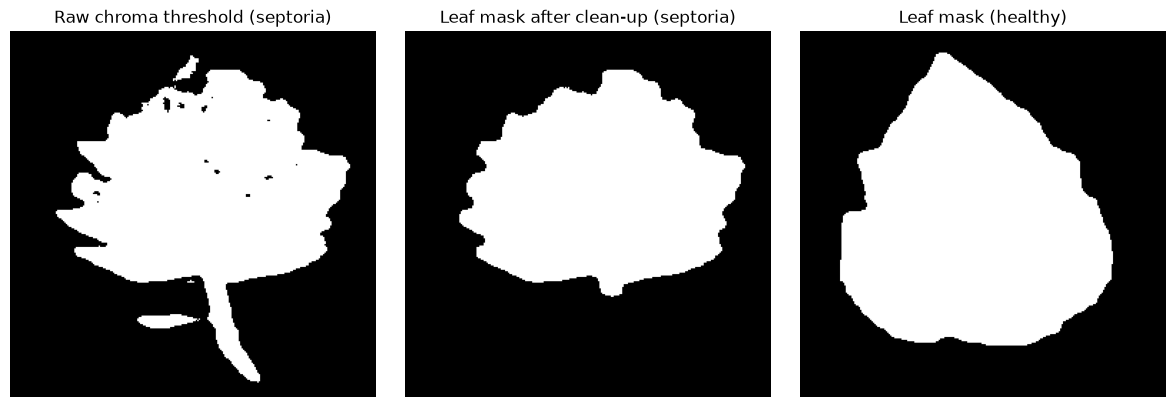

In [26]:
def largest_component(m):
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return m
    return (lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])).astype(np.uint8)

def remove_petiole(m, k=19):
    """The stem is thin, so a morphological 'opening' removes it; then we restore the blade edge detail."""
    opened = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    opened = largest_component(opened)
    grown = cv2.dilate(opened, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    return (m & grown).astype(np.uint8)

def chroma_map(img):
    lab = cv2.cvtColor(cv2.GaussianBlur(img, (5, 5), 0), cv2.COLOR_BGR2LAB).astype(float)
    return np.hypot(lab[..., 1] - 128, lab[..., 2] - 128)

def leaf_mask(img, chroma_thr=12.5):
    m = (chroma_map(img) > chroma_thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    m = largest_component(m)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)      # fill holes
    filled = np.zeros_like(m); cv2.drawContours(filled, cnts, -1, 1, -1)
    return remove_petiole(filled)

leaf_masks = {name: leaf_mask(im) for name, im in imgs.items()}
show([chroma_map(imgs["tomato_septoria_leaf_spot"]) > 12.5, leaf_masks["tomato_septoria_leaf_spot"], leaf_masks["tomato_healthy"]],
     ["Raw chroma threshold (septoria)", "Leaf mask after clean-up (septoria)", "Leaf mask (healthy)"], figsize=(12, 4))

## 3. Automatic lesion detection

Brown tissue in HSV colour space (OpenCV hue scale 0 to 179) is roughly **hue 3 to 26**, with some saturation and not very bright.
The yellow halo has hue about 28 or more and healthy green about 40 or more, so both are excluded.

tomato_healthy: lesion pixels = 0
tomato_septoria_leaf_spot: lesion pixels = 2310


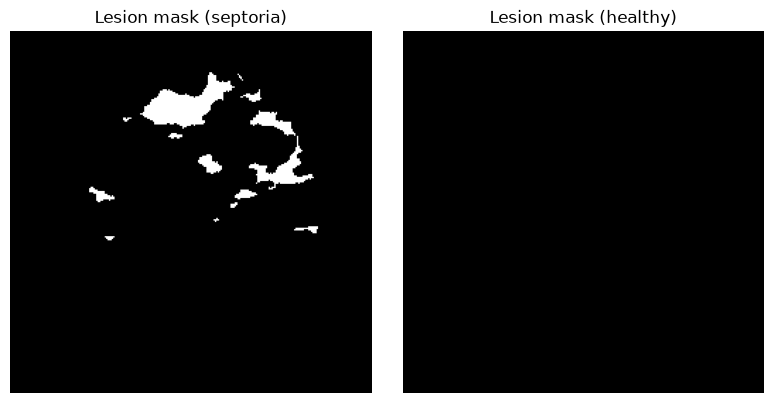

In [18]:
def lesion_mask(img, leaf, border=2, min_area=6):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(float)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    inner = cv2.erode(leaf, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * border + 1,) * 2))
    cand = ((h >= 3) & (h <= 26) & (s >= 40) & (v < 150) & (inner == 1)).astype(np.uint8)
    cand = cv2.morphologyEx(cand, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(cand)
    out = np.zeros_like(cand)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            out[lab == i] = 1
    return out

lesion_masks = {name: lesion_mask(im, leaf_masks[name]) for name, im in imgs.items()}
for name in imgs:
    print(f"{name}: lesion pixels = {int(lesion_masks[name].sum())}")
show([lesion_masks["tomato_septoria_leaf_spot"], lesion_masks["tomato_healthy"]], ["Lesion mask (septoria)", "Lesion mask (healthy)"], figsize=(8, 4))

## 4. Masks to polygons

A mask is a picture; a **polygon** is the annotation (a list of `[x, y]` points). Each separate blob becomes one polygon. `epsilon` controls how many points we keep: bigger means fewer points.

In [20]:
def mask_to_polygons(mask, epsilon=1.2, min_area=6):
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    polys = []
    for c in cnts:
        if cv2.contourArea(c) < min_area:
            continue
        approx = cv2.approxPolyDP(c, epsilon, True).reshape(-1, 2)
        if len(approx) >= 3:
            polys.append(approx)
    return polys

def polygons_to_mask(leaf_polys, lesion_polys, shape):
    m = np.zeros(shape[:2], np.uint8)
    for p in leaf_polys:   cv2.fillPoly(m, [p.astype(np.int32)], CLASSES["leaf"])
    for p in lesion_polys: cv2.fillPoly(m, [p.astype(np.int32)], CLASSES["lesion"])    # lesions on top
    return m

annotations = {}
for name, im in imgs.items():
    lp = mask_to_polygons(leaf_masks[name], epsilon=1.5, min_area=500)
    sp = mask_to_polygons(lesion_masks[name], epsilon=1.0, min_area=6)
    annotations[name] = {"leaf": lp, "lesion": sp}
    print(f"{name}: {len(lp)} leaf polygon ({sum(len(p) for p in lp)} points), {len(sp)} lesion polygons")

print("\nfirst 5 points of the septoria leaf polygon:\n", annotations["tomato_septoria_leaf_spot"]["leaf"][0][:5])

tomato_healthy: 1 leaf polygon (40 points), 0 lesion polygons
tomato_septoria_leaf_spot: 1 leaf polygon (60 points), 11 lesion polygons

first 5 points of the septoria leaf polygon:
 [[237  93]
 [232  87]
 [223  87]
 [207  82]
 [205  73]]


## 5. Severity

**Severity % = lesion pixels ÷ leaf pixels × 100.** The leaf area includes the lesions (they sit inside the leaf).
We rebuild the mask **from the polygons**, so the number reflects the annotation itself.

In [21]:
def severity_percent(sem):
    leaf_px = int(((sem == 1) | (sem == 2)).sum())
    return 100 * int((sem == 2).sum()) / leaf_px if leaf_px else 0.0

def grade(p):
    return "low" if p < 5 else "moderate" if p < 15 else "high"

semantic = {}
severity = {}
for name, im in imgs.items():
    semantic[name] = polygons_to_mask(annotations[name]["leaf"], annotations[name]["lesion"], im.shape)
    severity[name] = severity_percent(semantic[name])
    print(f"{name:18s} severity = {severity[name]:5.2f} %  ({grade(severity[name])})")

tomato_healthy     severity =  0.00 %  (low)
tomato_septoria_leaf_spot severity = 10.79 %  (moderate)


## 6. Overlay: check the result with your own eyes

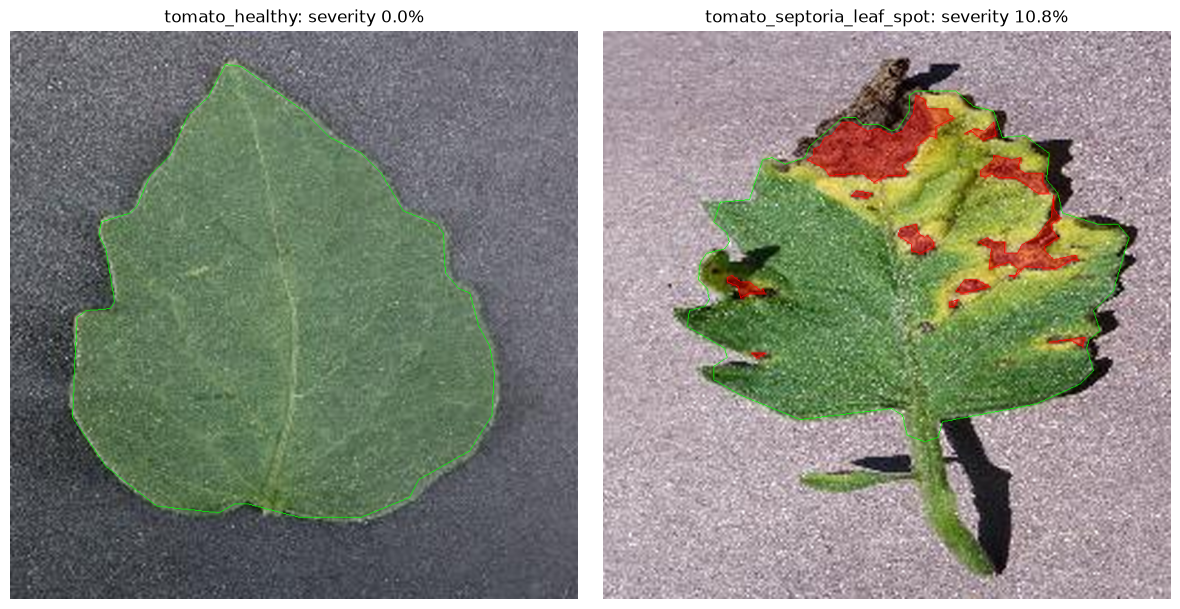

In [22]:
def make_overlay(img, sem, leaf_polys, lesion_polys, scale=3):
    big = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    red = big.copy()
    red[cv2.resize(sem, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST) == 2] = (0, 0, 255)
    ov = cv2.addWeighted(big, 0.6, red, 0.4, 0)
    for p in leaf_polys:   cv2.polylines(ov, [(p * scale).astype(np.int32)], True, (0, 255, 0), 1)
    for p in lesion_polys: cv2.polylines(ov, [(p * scale).astype(np.int32)], True, (0, 0, 255), 1)
    return ov

overlays = {n: make_overlay(imgs[n], semantic[n], annotations[n]["leaf"], annotations[n]["lesion"]) for n in imgs}
show(list(overlays.values()), [f"{n}: severity {severity[n]:.1f}%" for n in imgs], figsize=(12, 6))

**Review questions**
- Is every brown spot outlined? Which small dark spots were missed?
- Is the dead tissue at the top tip of the Septoria leaf included in the leaf outline?
- Are any shadows or stem parts wrongly included?
- Would a bigger or smaller `epsilon` give a better outline?

Write down at least three mistakes. Then fix them by hand in the next section.

## 7. Export: COCO JSON, YOLO-seg and masks

In [23]:
def bbox(poly):
    x, y, w, h = cv2.boundingRect(poly.astype(np.int32)); return [int(x), int(y), int(w), int(h)]

coco = {"images": [], "annotations": [], "categories": [{"id": 1, "name": "leaf"}, {"id": 2, "name": "lesion"}]}
ann_id = 1
for img_id, (name, im) in enumerate(imgs.items(), start=1):
    h, w = im.shape[:2]
    coco["images"].append({"id": img_id, "file_name": f"{name}.jpg", "width": w, "height": h})
    for label in ("leaf", "lesion"):
        for p in annotations[name][label]:
            coco["annotations"].append({"id": ann_id, "image_id": img_id, "category_id": CLASSES[label],
                "segmentation": [[int(v) for v in p.reshape(-1)]], "bbox": bbox(p),
                "area": float(cv2.contourArea(p.astype(np.int32))), "iscrowd": 0})
            ann_id += 1
(OUT / "annotations_coco.json").write_text(json.dumps(coco, indent=2))

for name, im in imgs.items():                                   # YOLO-seg: class x1 y1 x2 y2 ... normalised
    h, w = im.shape[:2]; lines = []
    for cid, label in ((0, "leaf"), (1, "lesion")):
        for p in annotations[name][label]:
            lines.append(f"{cid} " + " ".join(f"{v:.6f}" for v in (p.astype(float) / [w, h]).reshape(-1)))
    (OUT / f"{name}.txt").write_text("\n".join(lines))
    cv2.imwrite(str(OUT / f"{name}_mask.png"), semantic[name])
(OUT / "classes.txt").write_text("leaf\nlesion")

print("COCO annotations:", len(coco["annotations"]))
print("files:", sorted(p.name for p in OUT.iterdir()))

COCO annotations: 13
files: ['annotations_coco.json', 'classes.txt', 'tomato_healthy.txt', 'tomato_healthy_mask.png', 'tomato_septoria_leaf_spot.txt', 'tomato_septoria_leaf_spot_mask.png']
